In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from torch.utils.data import DataLoader

In [3]:
print(torch.__version__)


2.11.0+cu130


In [4]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [5]:
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 485kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.33MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]


In [6]:
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [9]:
images, labels = next(iter(train_loader))

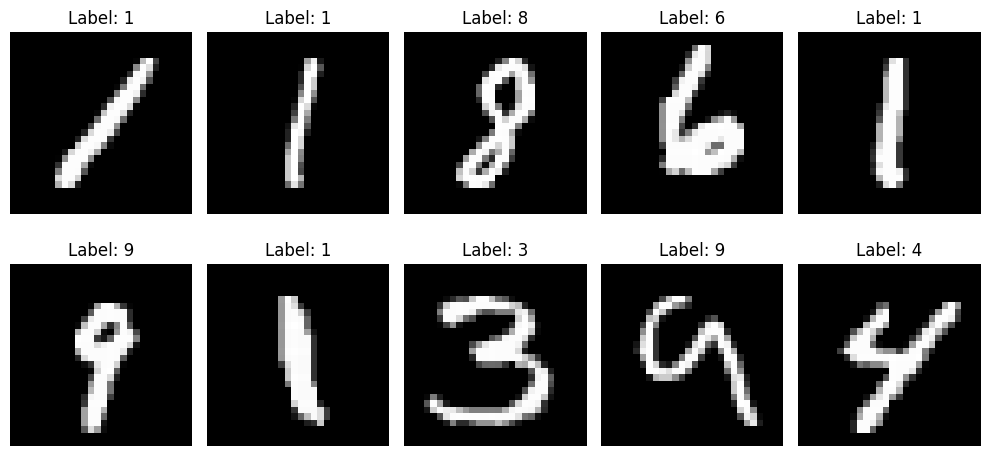

In [10]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(f"Label: {labels[i].item()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

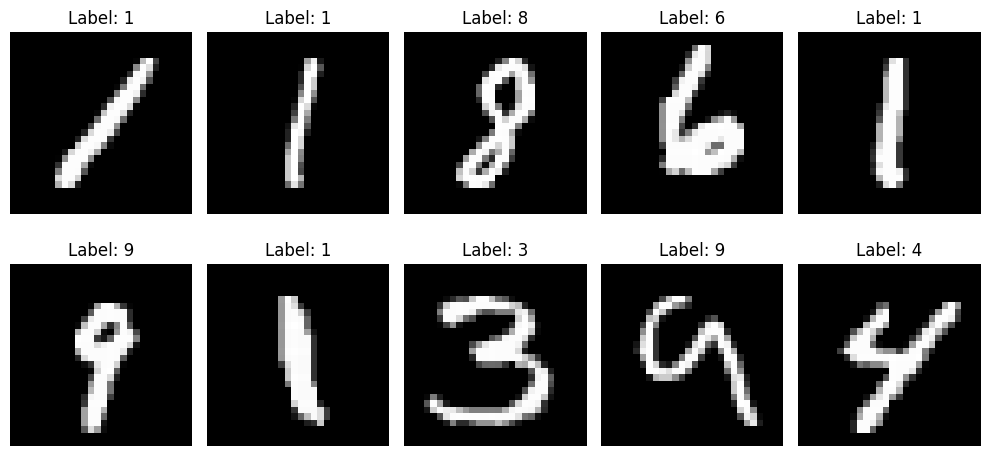

In [11]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(f"Label: {labels[i].item()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)

        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.relu(self.conv1(x))

        x = self.pool(x)

        x = self.relu(self.conv2(x))

        x = self.pool(x)

        x = x.view(-1, 64 * 7 * 7)

        x = self.relu(self.fc1(x))

        x = self.fc2(x)

        return x

In [13]:
model = CNN().to(device)

print(model)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


In [14]:
criterion = nn.CrossEntropyLoss()

In [15]:
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [16]:
num_epochs = 5

In [17]:
for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/5], Loss: 0.1878
Epoch [2/5], Loss: 0.0529
Epoch [3/5], Loss: 0.0362
Epoch [4/5], Loss: 0.0281
Epoch [5/5], Loss: 0.0213


In [18]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.02%


In [19]:
def fgsm_attack(image, epsilon, data_grad):

    sign_data_grad = data_grad.sign()

    perturbed_image = image + epsilon * sign_data_grad

    perturbed_image = torch.clamp(perturbed_image, 0, 1)

    return perturbed_image

In [20]:
# Load one batch of test images
images, labels = next(iter(test_loader))

images = images.to(device).requires_grad_(True)
labels = labels.to(device)

# Clear previous gradients
model.zero_grad()

# Get predictions
outputs = model(images)

# Calculate loss
loss = criterion(outputs, labels)

# Calculate gradients
loss.backward()

# Store gradients of input images
data_grad = images.grad.data

In [21]:
epsilon = 0.1

perturbed_images = fgsm_attack(images, epsilon, data_grad)

print("Original images shape:", images.shape)
print("Adversarial images shape:", perturbed_images.shape)

Original images shape: torch.Size([64, 1, 28, 28])
Adversarial images shape: torch.Size([64, 1, 28, 28])


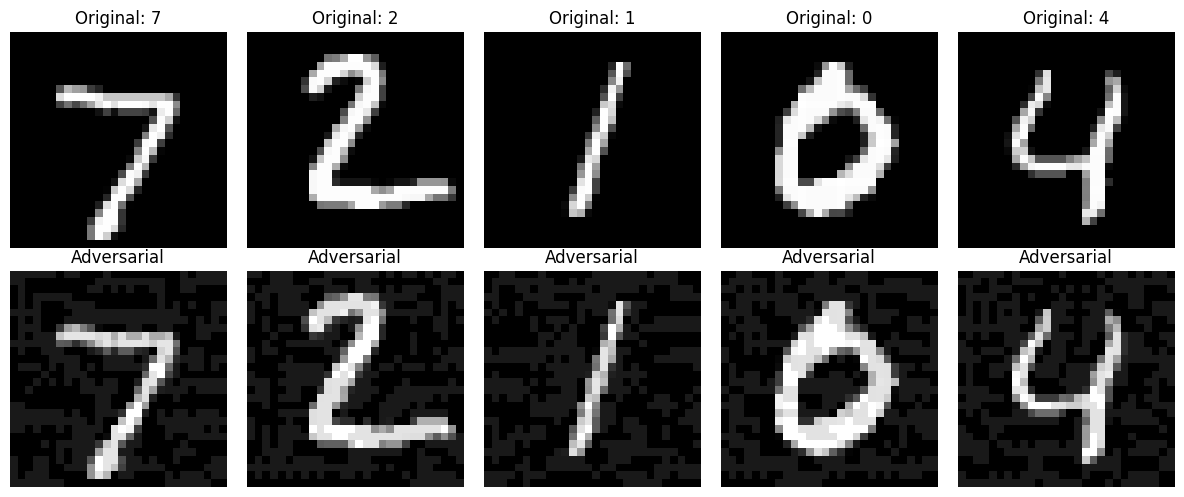

In [22]:
plt.figure(figsize=(12, 5))

for i in range(5):

    # Original image
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].detach().cpu().squeeze(), cmap="gray")
    plt.title(f"Original: {labels[i].item()}")
    plt.axis("off")

    # Adversarial image
    plt.subplot(2, 5, i + 6)
    plt.imshow(perturbed_images[i].detach().cpu().squeeze(), cmap="gray")
    plt.title("Adversarial")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
model.eval()

with torch.no_grad():

    # Predictions on original images
    clean_outputs = model(images)

    # Predictions on adversarial images
    adv_outputs = model(perturbed_images)

    _, clean_predicted = torch.max(clean_outputs, 1)

    _, adv_predicted = torch.max(adv_outputs, 1)

# Calculate accuracy
clean_accuracy = 100 * (clean_predicted == labels).sum().item() / len(labels)

adv_accuracy = 100 * (adv_predicted == labels).sum().item() / len(labels)

print(f"Original Accuracy: {clean_accuracy:.2f}%")
print(f"Adversarial Accuracy: {adv_accuracy:.2f}%")

Original Accuracy: 100.00%
Adversarial Accuracy: 81.25%


In [24]:
epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]

print("Epsilon values:", epsilons)

Epsilon values: [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]


In [25]:
def evaluate_fgsm(epsilon):

    correct = 0
    total = 0

    model.eval()

    for images, labels in test_loader:

        images = images.to(device).detach().requires_grad_(True)
        labels = labels.to(device)

        model.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        data_grad = images.grad.detach()

        perturbed_images = fgsm_attack(
            images, epsilon, data_grad
        )

        with torch.no_grad():
            outputs = model(perturbed_images)
            _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy


accuracies = []

for eps in epsilons:

    acc = evaluate_fgsm(eps)

    accuracies.append(acc)

    print(f"Epsilon: {eps:.2f} | Accuracy: {acc:.2f}%")

Epsilon: 0.00 | Accuracy: 99.02%
Epsilon: 0.05 | Accuracy: 95.56%
Epsilon: 0.10 | Accuracy: 84.50%
Epsilon: 0.15 | Accuracy: 63.08%
Epsilon: 0.20 | Accuracy: 36.88%
Epsilon: 0.25 | Accuracy: 20.13%
Epsilon: 0.30 | Accuracy: 12.57%


In [27]:
def evaluate_fgsm(epsilon):

    correct = 0
    total = 0

    model.eval()

    for images, labels in test_loader:

        images = images.to(device).detach().requires_grad_(True)
        labels = labels.to(device)

        model.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        data_grad = images.grad.detach()

        perturbed_images = fgsm_attack(
            images, epsilon, data_grad
        )

        with torch.no_grad():
            outputs = model(perturbed_images)
            _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy


accuracies = []

for eps in epsilons:

    acc = evaluate_fgsm(eps)

    accuracies.append(acc)

    print(f"Epsilon: {eps:.2f} | Accuracy: {acc:.2f}%")

Epsilon: 0.00 | Accuracy: 99.02%
Epsilon: 0.05 | Accuracy: 95.56%
Epsilon: 0.10 | Accuracy: 84.50%
Epsilon: 0.15 | Accuracy: 63.08%
Epsilon: 0.20 | Accuracy: 36.88%
Epsilon: 0.25 | Accuracy: 20.13%
Epsilon: 0.30 | Accuracy: 12.57%


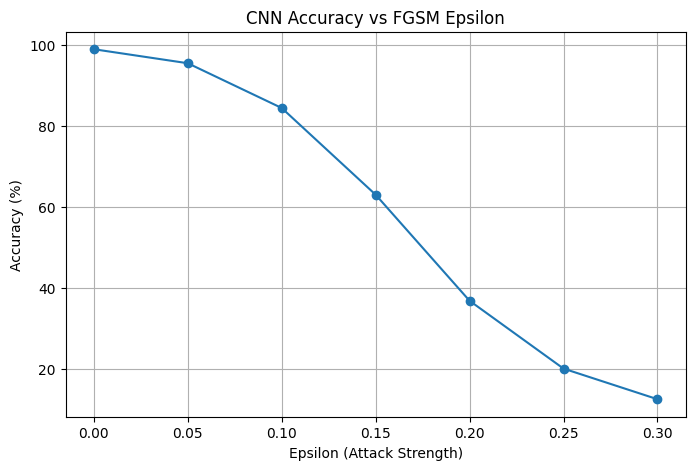

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(epsilons, accuracies, marker='o')

plt.title("CNN Accuracy vs FGSM Epsilon")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Accuracy (%)")

plt.xticks(epsilons)
plt.grid(True)

plt.show()

In [29]:
accuracy_drop = [
    accuracies[0] - acc for acc in accuracies
]

for eps, drop in zip(epsilons, accuracy_drop):

    print(f"Epsilon: {eps:.2f} | Accuracy Drop: {drop:.2f}%")

Epsilon: 0.00 | Accuracy Drop: 0.00%
Epsilon: 0.05 | Accuracy Drop: 3.46%
Epsilon: 0.10 | Accuracy Drop: 14.52%
Epsilon: 0.15 | Accuracy Drop: 35.94%
Epsilon: 0.20 | Accuracy Drop: 62.14%
Epsilon: 0.25 | Accuracy Drop: 78.89%
Epsilon: 0.30 | Accuracy Drop: 86.45%


In [30]:
def calculate_asr(epsilon):

    successful_attacks = 0
    total_correct = 0

    model.eval()

    for images, labels in test_loader:

        images = images.to(device).detach().requires_grad_(True)
        labels = labels.to(device)

        model.zero_grad()

        # Original predictions
        outputs = model(images)
        _, clean_predicted = torch.max(outputs, 1)

        # Identify correctly classified images
        clean_correct = (clean_predicted == labels)

        # Calculate gradients
        loss = criterion(outputs, labels)
        loss.backward()

        data_grad = images.grad.detach()

        # Generate adversarial images
        perturbed_images = fgsm_attack(
            images, epsilon, data_grad
        )

        # Adversarial predictions
        with torch.no_grad():
            adv_outputs = model(perturbed_images)
            _, adv_predicted = torch.max(adv_outputs, 1)

        # Count successful attacks
        successful_attacks += (
            clean_correct & (adv_predicted != labels)
        ).sum().item()

        total_correct += clean_correct.sum().item()

    asr = 100 * successful_attacks / total_correct

    return asr


asr_values = []

for eps in epsilons:

    asr = calculate_asr(eps)

    asr_values.append(asr)

    print(f"Epsilon: {eps:.2f} | ASR: {asr:.2f}%")

Epsilon: 0.00 | ASR: 0.00%
Epsilon: 0.05 | ASR: 3.49%
Epsilon: 0.10 | ASR: 14.66%
Epsilon: 0.15 | ASR: 36.30%
Epsilon: 0.20 | ASR: 62.75%
Epsilon: 0.25 | ASR: 79.67%
Epsilon: 0.30 | ASR: 87.31%


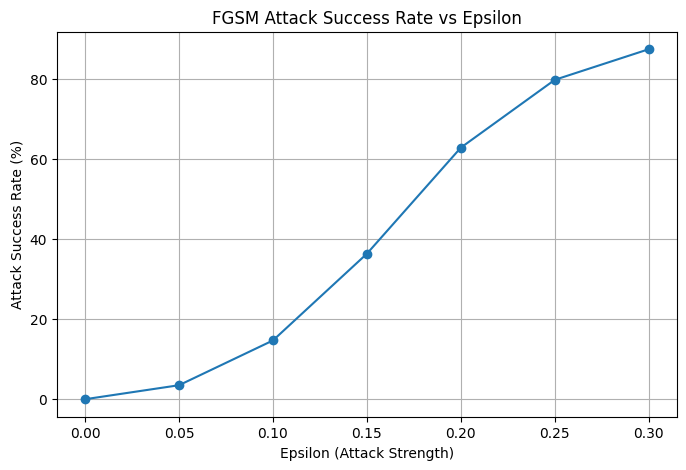

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(epsilons, asr_values, marker='o')

plt.title("FGSM Attack Success Rate vs Epsilon")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Attack Success Rate (%)")

plt.xticks(epsilons)
plt.grid(True)

plt.show()

In [32]:
results_df = pd.DataFrame({
    "Epsilon": epsilons,
    "Accuracy (%)": accuracies,
    "Accuracy Drop (%)": accuracy_drop,
    "Attack Success Rate (%)": asr_values
})

print(results_df)

   Epsilon  Accuracy (%)  Accuracy Drop (%)  Attack Success Rate (%)
0     0.00         99.02               0.00                 0.000000
1     0.05         95.56               3.46                 3.494244
2     0.10         84.50              14.52                14.663704
3     0.15         63.08              35.94                36.295698
4     0.20         36.88              62.14                62.754999
5     0.25         20.13              78.89                79.670774
6     0.30         12.57              86.45                87.305595


In [33]:
results_df.to_csv("fgsm_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [34]:
torch.save(model.state_dict(), "fgsm_cnn_model.pth")

print("Model saved successfully!")

Model saved successfully!


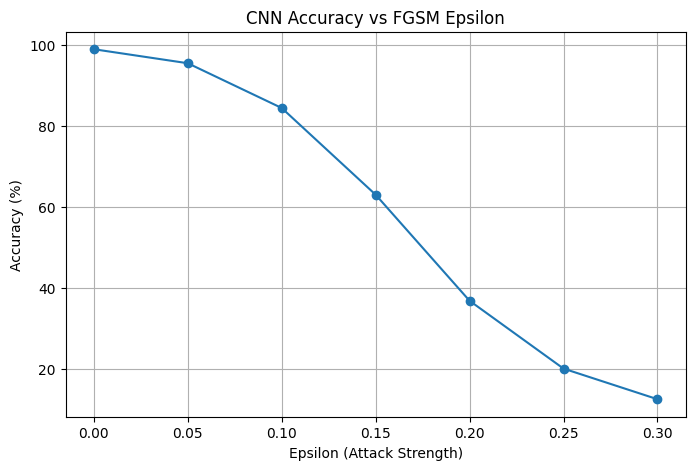

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(epsilons, accuracies, marker='o')

plt.title("CNN Accuracy vs FGSM Epsilon")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Accuracy (%)")

plt.xticks(epsilons)
plt.grid(True)

plt.savefig("accuracy_vs_epsilon.png", dpi=300, bbox_inches="tight")

plt.show()

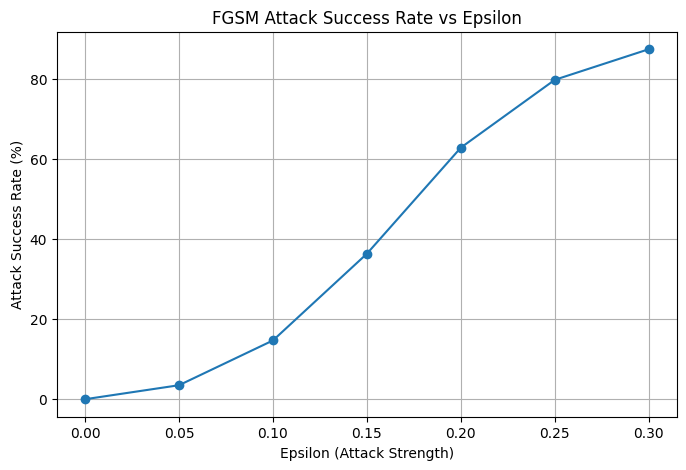

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(epsilons, asr_values, marker='o')

plt.title("FGSM Attack Success Rate vs Epsilon")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Attack Success Rate (%)")

plt.xticks(epsilons)
plt.grid(True)

plt.savefig("asr_vs_epsilon.png", dpi=300, bbox_inches="tight")

plt.show()

In [37]:
import zipfile

files_to_save = [
    "fgsm_results.csv",
    "fgsm_cnn_model.pth",
    "accuracy_vs_epsilon.png",
    "asr_vs_epsilon.png"
]

with zipfile.ZipFile("FGSM_Project_Results.zip", "w") as zip_file:

    for file in files_to_save:
        zip_file.write(file)

print("Project results packaged successfully!")

Project results packaged successfully!
